<a href="https://colab.research.google.com/github/Kristina-Ga/ML/blob/main/car_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

**Оценка автомобиля**

**0. Описание задачи**

Таблица содержит данные о 10 000 автомобилях, выставленных на оценку. Датасет содержит реалистичные и коррелирующие между собой данные, имитирующие реальный рынок подержанных и новых автомобилей.

Для каждой машины указаны её характеристики: марка и модель, год выпуска, цена в долларах, регион продажи, тип топлива, коробка передач, объем двигателя, мощность, пробег, количество владельцев, а также текстовый отзыв клиента.

Целевой признак — `evaluation_class`. Это оценка автомобиля, которая может принимать одно из четырех значений: `unacceptable`, `acceptable`, `good` или `very_good`.


**1. Чтение данных**


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving car_evaluation_dataset.csv to car_evaluation_dataset.csv


In [ ]:
import io
data_raw = pd.read_csv(io.BytesIO(uploaded['car_evaluation_dataset.csv']))

Вначале посмотрим на размеры таблицы: количество строк (каждая строка соответствует одному автомобилю) и количество столбцов (каждый столбец соответствует конкретному признаку):

In [ ]:
data_raw.shape

(10000, 22)

In [ ]:
data_raw

,car_id,brand,model,manufacture_year,inspection_date,region,buying_price_level,price_usd,maintenance_cost_level,annual_maintenance_usd,...,luggage_boot_size,safety_rating,fuel_type,transmission,engine_size_l,horsepower,mileage_km,owner_count,customer_review_text,evaluation_class
0,CAR101977,Maruti Suzuki,Maruti-S787,2013,2025-03-15,North America,vhigh,35415.74,med,889.71,...,big,high,Petrol,Manual,2.0,114.0,151369.0,1.0,"Decent runabout, a few compromises but accepta...",acceptable
1,CAR103880,Kia,Kia-X498,2007,2023-05-13,Western Europe,high,31249.33,high,1646.84,...,med,low,Hybrid,Automatic,1.8,86.0,87809.0,2.0,Would not recommend; poor value for the runnin...,unacceptable
2,CAR100052,Hyundai,Hyundai-SE713,2020,2024-03-25,Southeast Asia,high,35062.70,high,2290.45,...,med,med,Petrol,Automatic,2.3,127.0,55745.0,4.0,Feels outdated and unsafe for the price paid.,unacceptable
3,CAR102551,Chevrolet,Chevrolet-S789,2011,2025-11-08,Western Europe,med,23722.04,med,974.69,...,med,high,Petrol,Manual,2.1,111.0,212742.0,2.0,"Frequent trips to the mechanic, disappointing ...",unacceptable
4,CAR102246,Honda,Honda-Sport936,2013,2024-02-14,Africa,low,16179.22,med,1213.57,...,small,med,Petrol,Manual,0.9,60.0,120923.0,4.0,"Frequent trips to the mechanic, disappointing ...",unacceptable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,CAR100919,Renault,Renault-LX106,2021,2024-02-04,North America,med,17799.46,low,473.65,...,med,med,Electric,Manual,0.8,94.0,91256.0,2.0,Gets the basics right without breaking the bank.,acceptable
9996,CAR104307,Renault,Renault-SE570,2016,2025-09-15,Western Europe,med,21256.76,vhigh,4496.14,...,small,high,Diesel,Manual,2.2,142.0,167397.0,2.0,Gets the basics right without breaking the bank.,acceptable
9997,CAR105699,BMW,BMW-Plus639,2011,2023-05-24,East Asia,low,12533.69,low,339.45,...,small,med,Petrol,Manual,1.5,94.0,237780.0,1.0,Would not recommend; poor value for the runnin...,unacceptable
9998,CAR100537,Toyota,Toyota-LX750,2021,2023-03-22,South Asia,low,9335.74,high,1931.74,...,med,med,Electric,Automatic,1.7,125.0,52620.0,3.0,Would not recommend; poor value for the runnin...,unacceptable


**2. Разбиение данных на обучающую и тестовую выборки**

Для предсказания оценки автомобиля будем использовать все входные признаки, кроме трех: `car_id`, `inspection_date` и `customer_review_text`.

`car_id` - уникальный идентификатор, не несет физического смысла.

`customer_review_text` - это длинный текст отзыва. Алгоритму KNN нужны только числа.

`inspection_date` - дата. Её убираем для простоты.

In [ ]:
X = data_raw.drop(['evaluation_class', 'car_id', 'inspection_date', 'customer_review_text'], axis=1)
y = data_raw['evaluation_class']

In [ ]:
type(X)

pandas.core.frame.DataFrame

In [ ]:
type(y)

pandas.core.series.Series

Разобьем данные на обучающую и тестовую выборки в пропорции 3:1 (75% - обучающая выборка, 25% - тестовая):

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

N_train, d = X_train.shape
N_test, d = X_test.shape

N_train, N_test, d

(7500, 2500, 18)

**3. Визуализация данных и вычисление основных характеристик**

Информация о числовых признаках:

In [ ]:
data_raw.describe()

,manufacture_year,price_usd,annual_maintenance_usd,engine_size_l,horsepower,mileage_km,owner_count
count,10000.000000,10000.000000,9850.000000,10000.000000,9750.000000,9602.000000,9900.000000
mean,2014.545500,26863.953721,1514.796417,1.630870,97.711487,150220.590398,2.016263
std,5.737824,18184.416118,1107.287796,0.613555,35.620608,89435.841824,1.129390
min,2005.000000,4223.900000,250.040000,0.800000,60.000000,2093.000000,1.000000
25%,2010.000000,13461.935000,657.980000,1.100000,63.000000,77106.000000,1.000000
50%,2014.000000,22140.580000,1167.990000,1.600000,91.000000,138639.500000,2.000000
75%,2020.000000,35350.160000,2112.357500,2.000000,120.750000,210341.000000,3.000000
max,2024.000000,154064.420000,4799.890000,4.300000,274.000000,637000.000000,5.000000


Корреляционная матрица:

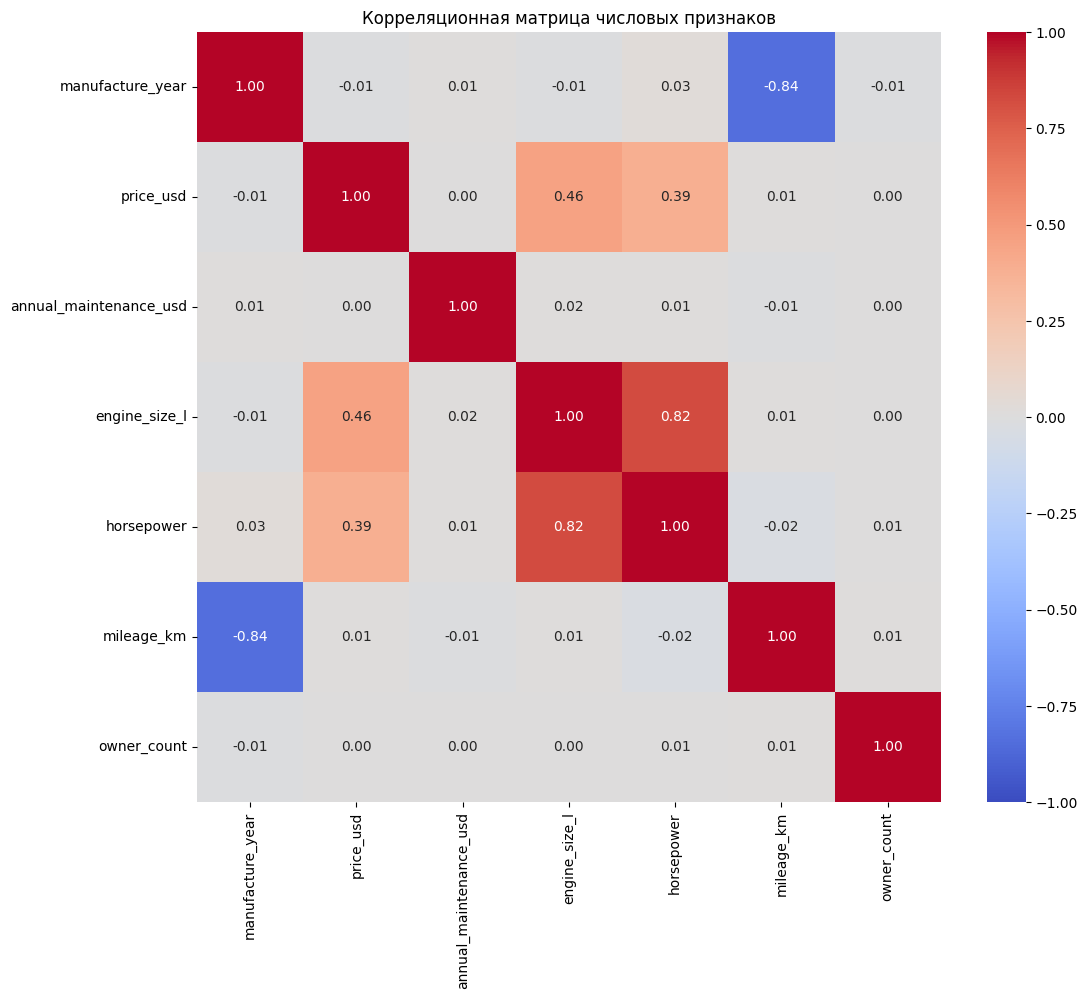

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = data_raw.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))
sns.heatmap(data_raw[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков')
plt.show()

Визуализация данных

Построим диаграммы рассеивания, чтобы увидеть, как целевая переменная `evaluation_class` зависит от числовых признаков (цены, года выпуска и пробега).

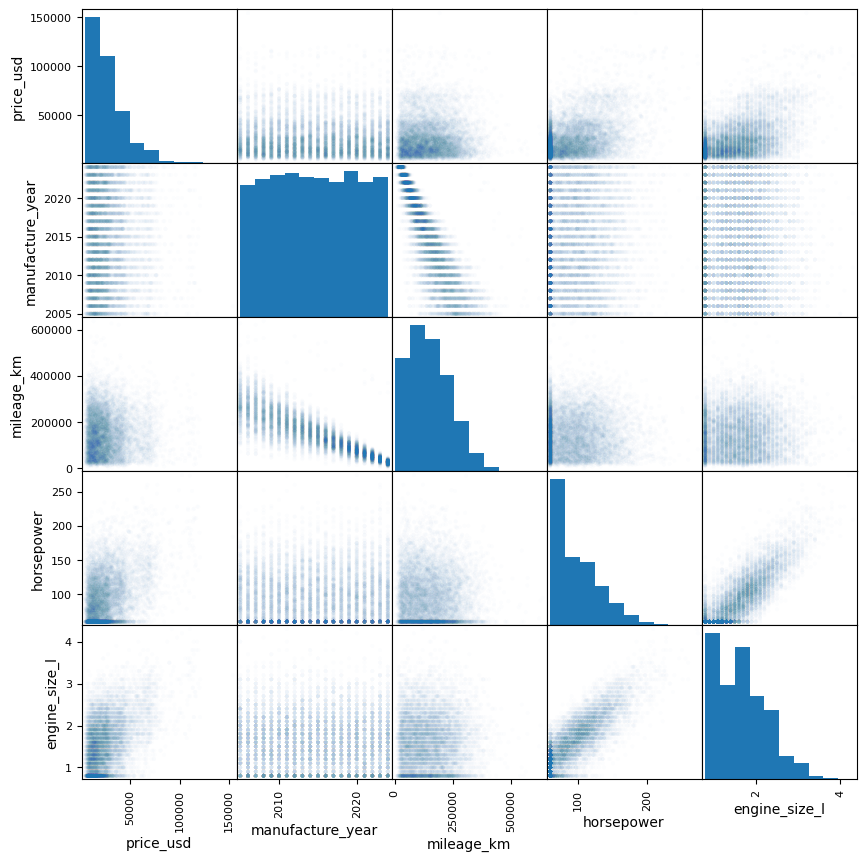

In [ ]:
from pandas.plotting import scatter_matrix

cols_for_matrix = ['price_usd', 'manufacture_year', 'mileage_km', 'horsepower', 'engine_size_l']
scatter_matrix(data_raw[cols_for_matrix], alpha=0.01, figsize=(10, 10))
pass

Интерпретация:

1. По таблице describe() видно, что числа в колонках очень разные (цена в тысячах, пробег в сотнях тысяч). Также видно, что в колонках mileage_km и horsepower есть пропуски (значений меньше 10000). Значит, нам нужно будет сделать нормализацию и заполнить пропуски

2. Есть большая связь между годом выпуска и пробегом (-0.84) (чем новее машина, тем меньше пробег), большая связь между мощностью и объемом двигателя (0.82). Цена средне связана с объемом двигателя (0.46)

3. На диаграммах видно, что цена сильно зависит от года выпуска. Также на графиках есть точки, которые сильно выбиваются из общей массы( выбросы)

**4. Выбросы**

В предыдущем пункте было заметно, что в данных есть точки, которые сильно выбиваются из общей массы.

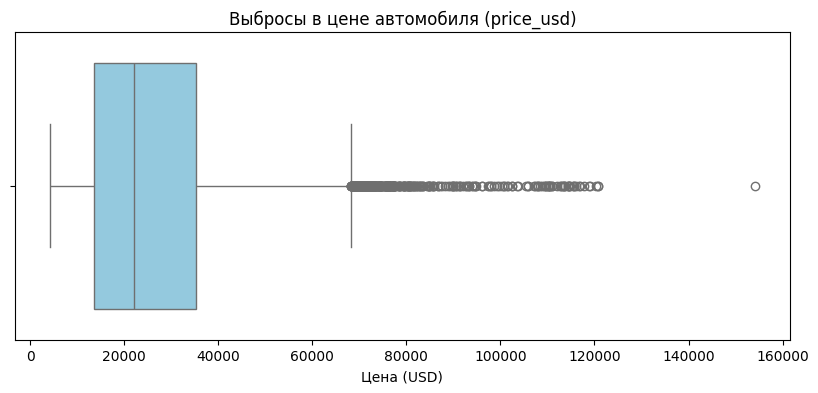

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(data=data_raw, x='price_usd', color='skyblue')
plt.title('Выбросы в цене автомобиля (price_usd)')
plt.xlabel('Цена (USD)')
plt.show()

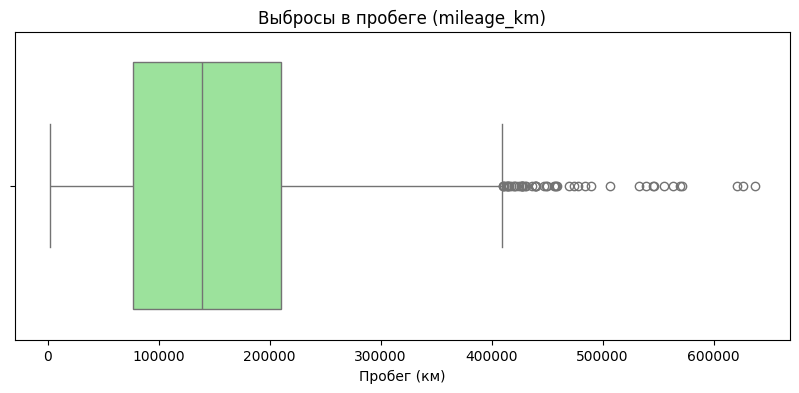

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=data_raw, x='mileage_km', color='lightgreen')
plt.title('Выбросы в пробеге (mileage_km)')
plt.xlabel('Пробег (км)')
plt.show()

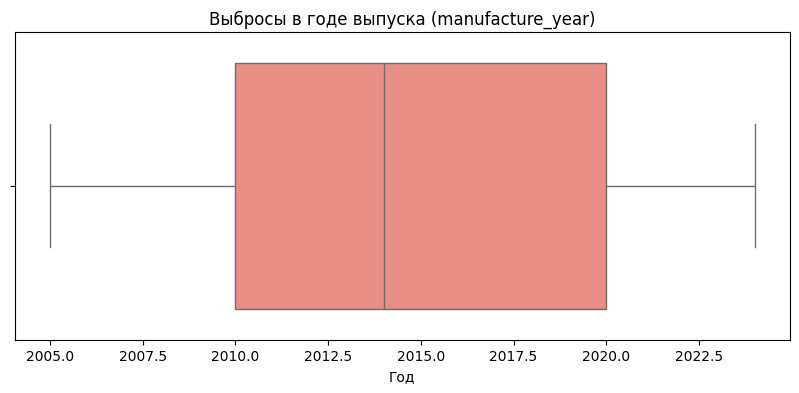

In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=data_raw, x='manufacture_year', color='salmon')
plt.title('Выбросы в годе выпуска (manufacture_year)')
plt.xlabel('Год')
plt.show()

1. На графике цены видно много выбросов. Есть машины с высокой ценой (более 70 000 долларов), которые выделяются на фоне остальных
2. На графике пробега также есть выбросы - машины с очень большим пробегом
3. На графике года выпуска выбросов нет, все значения находятся в пределах (от 2005 до 2024 года).

Так как выбросы в цене и пробеге отражают реальные рыночные ситуации, мы оставляем их в данных. Удаление таких объектов могло бы привести к потере важной информации и ухудшению качества модели

5. Обработка пропущенных значений

Пропущенные значения

In [ ]:
data_raw.isnull()

,car_id,brand,model,manufacture_year,inspection_date,region,buying_price_level,price_usd,maintenance_cost_level,annual_maintenance_usd,...,luggage_boot_size,safety_rating,fuel_type,transmission,engine_size_l,horsepower,mileage_km,owner_count,customer_review_text,evaluation_class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
data_raw.isnull().sum()

,0
car_id,0
brand,0
model,0
manufacture_year,0
inspection_date,0
region,0
buying_price_level,0
price_usd,0
maintenance_cost_level,0
annual_maintenance_usd,150


Мы видим, что в некоторых признаках есть пропуски. Их нужно заполнить.
Для числовых признаков заполним пропуски медианой. В категориальных признаках пропусков нет, поэтому их обработка не требуется.

In [ ]:
from sklearn.impute import SimpleImputer
import numpy as np

imp_num = SimpleImputer(missing_values=np.nan, strategy='median')
imp_num.fit(X_train[['annual_maintenance_usd', 'horsepower', 'mileage_km', 'owner_count']])

SimpleImputer(strategy='median')

In [ ]:
X_train[['annual_maintenance_usd', 'horsepower', 'mileage_km', 'owner_count']] = imp_num.transform(X_train[['annual_maintenance_usd', 'horsepower', 'mileage_km', 'owner_count']])
X_test[['annual_maintenance_usd', 'horsepower', 'mileage_km', 'owner_count']] = imp_num.transform(X_test[['annual_maintenance_usd', 'horsepower', 'mileage_km', 'owner_count']])

In [ ]:
X_train.isna().sum()

,0
manufacture_year,0
price_usd,0
annual_maintenance_usd,0
engine_size_l,0
horsepower,0
...,...
safety_rating_med,0
fuel_type_Electric,0
fuel_type_Hybrid,0
fuel_type_Petrol,0


После заполнения пропусков в данных не осталось

**6. Обработка категориальных признаков**

Алгоритмы из библиотеки scikit-learn (почти) не умеют работать напрямую с категориальными признаками. Поэтому их вначале надо закодировать с помощью числовых признаков.

В этом датасете категориальных колонок гораздо больше (чем в примере из лекции), и прописывать их все вручную в скобках очень долго, поэтому сделаем то же самое, но автоматически, используя `pd.get_dummies`

Примечание: Признак `model` (название модели, к примеру, `Kia-X498`) имеет слишком много уникальных значений (почти столько же, сколько строк в таблице). Если мы применим к нему One-Hot Encoding, это плохо для KNN, Поэтому удалим колонку `model`, но оставим общую марку `brand`.

In [ ]:
import pandas as pd

X_train = X_train.drop(columns=['model'], errors='ignore')
X_test = X_test.drop(columns=['model'], errors='ignore')

X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(f"Размер X_train: {X_train.shape}")
print(f"Размер X_test: {X_test.shape}")

Размер X_train после кодирования: (7500, 48)
Размер X_test после кодирования: (2500, 48)


**7. Нормализация**

Перед применением алгоритмов машинного обучения количественные признаки полезно нормализовать. Так как признаки имеют разный масштаб (цена в тысячах, пробег в сотнях тысяч), мы выполним стандартизацию - приведем все значения к нулевому среднему и единичному стандартному отклонению.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [ ]:
X_train_scaled.describe()

,manufacture_year,price_usd,annual_maintenance_usd,engine_size_l,horsepower,mileage_km,owner_count,brand_Chevrolet,brand_Ford,brand_Honda,...,seating_capacity_4,seating_capacity_more,luggage_boot_size_med,luggage_boot_size_small,safety_rating_low,safety_rating_med,fuel_type_Electric,fuel_type_Hybrid,fuel_type_Petrol,transmission_Manual
count,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,...,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03,7.500000e+03
mean,-5.888978e-15,-1.061077e-16,-3.031649e-17,-3.979039e-16,-4.215887e-17,-1.080025e-16,5.305386e-17,7.579123e-18,8.431774e-17,-4.073778e-17,...,1.193712e-16,-6.631732e-18,1.468455e-17,3.126388e-17,-6.939634e-17,-1.103710e-16,2.652693e-17,1.800042e-17,-7.579123e-17,-6.158037e-18
std,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,...,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00,1.000067e+00
min,-1.669861e+00,-1.250369e+00,-1.147420e+00,-1.356861e+00,-1.072884e+00,-1.682396e+00,-9.104968e-01,-2.729443e-01,-2.626503e-01,-2.737893e-01,...,-9.497921e-01,-6.575646e-01,-8.546947e-01,-6.180445e-01,-6.114556e-01,-8.991865e-01,-3.155084e-01,-4.506439e-01,-8.523610e-01,-1.108226e+00
25%,-7.976827e-01,-7.390068e-01,-7.743088e-01,-8.687350e-01,-9.590148e-01,-7.915444e-01,-9.104968e-01,-2.729443e-01,-2.626503e-01,-2.737893e-01,...,-9.497921e-01,-6.575646e-01,-8.546947e-01,-6.180445e-01,-6.114556e-01,-8.991865e-01,-3.155084e-01,-4.506439e-01,-8.523610e-01,-1.108226e+00
50%,7.449566e-02,-2.499491e-01,-3.090207e-01,-5.519083e-02,-1.619329e-01,-1.306039e-01,-1.820280e-02,-2.729443e-01,-2.626503e-01,-2.737893e-01,...,-9.497921e-01,-6.575646e-01,-8.546947e-01,-6.180445e-01,-6.114556e-01,-8.991865e-01,-3.155084e-01,-4.506439e-01,-8.523610e-01,9.023433e-01
75%,9.466740e-01,4.572320e-01,5.424299e-01,5.956445e-01,6.066818e-01,6.529085e-01,8.740912e-01,-2.729443e-01,-2.626503e-01,-2.737893e-01,...,1.052862e+00,1.520763e+00,1.170008e+00,1.618006e+00,1.635442e+00,1.112116e+00,-3.155084e-01,-4.506439e-01,1.173212e+00,9.023433e-01
max,1.644417e+00,6.967279e+00,2.979228e+00,4.337948e+00,5.019100e+00,5.559539e+00,2.658679e+00,3.663752e+00,3.807344e+00,3.652444e+00,...,1.052862e+00,1.520763e+00,1.170008e+00,1.618006e+00,1.635442e+00,1.112116e+00,3.169488e+00,2.219047e+00,1.173212e+00,9.023433e-01


**8. Метод  k  ближайших соседей ( k NN,  k  nearest neighbours)**

В качестве алгоритма выбран метод K-ближайших соседей (KNeighborsClassifier).
 Обоснование: Выбран метод K-ближайших соседей. Он прост в реализации, не требует сложной настройки и не делает предположений о распределении данных. Однако стоит отметить, что KNN чувствителен к масштабу признаков (поэтому была проведена нормализация) и плохо работает при большом количестве признаков.
 Обучим модель с количеством соседей k=5.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=7)
model.fit(X_train_scaled, y_train)

model

KNeighborsClassifier(n_neighbors=7)

In [ ]:
y_train_predict = model.predict(X_train_scaled)
y_test_predict = model.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_train = accuracy_score(y_train, y_train_predict)
accuracy_test = accuracy_score(y_test, y_test_predict)

accuracy_train, accuracy_test

(0.7705333333333333, 0.6916)

In [ ]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, y_test_predict)
conf_matrix

array([[ 148,    3,  395,    4],
       [  36,    1,   75,    1],
       [ 166,    5, 1579,    0],
       [  41,    1,   44,    1]])

**9.**

Вычисление ошибок на обучающей и тестовой выборках. Матрица рассогласования

Вычислим точность на обучающей и тестовой выборках. Так как у нас задача классификации, мы также построим матрицу рассогласования, чтобы увидеть, какие классы модель путает.

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_train = accuracy_score(y_train, y_train_predict)

accuracy_test = accuracy_score(y_test, y_test_predict)

print(f"Точность на обучающей выборке: {accuracy_train:.4f}")
print(f"Точность на тестовой выборке: {accuracy_test:.4f}")

Точность на обучающей выборке: 0.7705
Точность на тестовой выборке: 0.6916


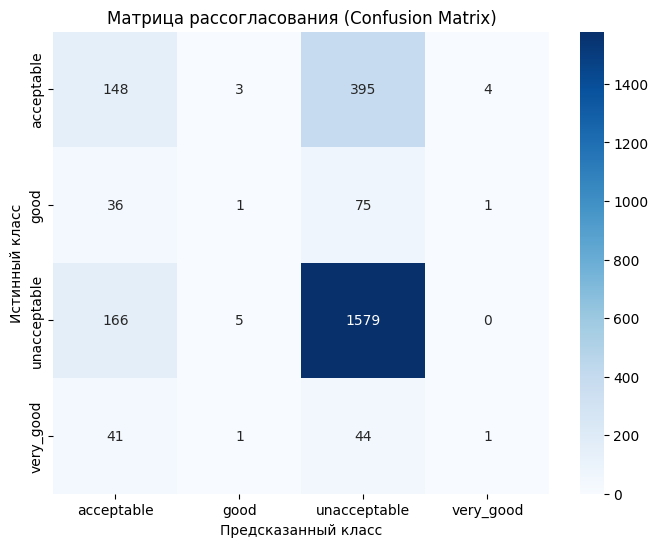

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

conf_matrix = confusion_matrix(y_test, y_test_predict)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица рассогласования (Confusion Matrix)')
plt.show()

Комментарий:
1. Точность на обучающей выборке (0.7705) выше, чем на тестовой (0.6916). Это нормально, так как модель видела обучающие данные. Небольшая разница говорит о том, что модель не сильно переобучилась
2. По матрице видно, что модель хорошо предсказывает класс `unacceptable` (много правильных ответов по диагонали) и `acceptable`. Однако она часто путает класс `acceptable` с `unacceptable` (большое число вне диагонали). Классы `good` и `very_good` предсказываются плохо из-за сильного дисбаланса классов в датасете (их очень мало).

Подбор оптимального значения гиперпараметра k

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50])

params = {
    'n_neighbors': k_arr,
}

model_cv = GridSearchCV(KNeighborsClassifier(), params, scoring='accuracy')
model_cv.fit(X_train_scaled, y_train)

model_cv.best_score_, model_cv.best_params_

(np.float64(0.7158666666666667), {'n_neighbors': np.int64(15)})

In [ ]:
model_cv.best_params_['n_neighbors']

np.int64(15)

Оптимальное значение гиперпараметра k = 15

**10. Выводы**

Была решена задача классификации (оценки) автомобилей.

1. Датасет оказался "грязным" - в нем были пропуски (их мы заполнили медианой), выбросы (оставили, так как это реальные дорогие машины) и сильный дисбаланс классов (плохих машин больше, чем хороших).
2. Текстовые признаки перевели в числа через One-Hot Encoding, а все числовые признаки нормализовали, чтобы KNN работал корректно.
3. Обучили KNN. Подобрали оптимальное количество соседей: k = 15.
4. Точность на тесте составила около 70%. Матрица ошибок показала, что модель хорошо определяет класс `unacceptable`, но путает его с `acceptable`. Классы `good` и `very_good` предсказываются плохо из-за того, что их слишком мало в данных.